C:\Users\brahim\AppData\Local\Temp\ipykernel_7652\3586266260.py:34: FutureWarning: `square` is deprecated since version 0.25 and will be removed in version 0.27. Use `skimage.morphology.footprint_rectangle` instead.
  return morphology.binary_opening(m, morphology.square(sq))
C:\Users\brahim\AppData\Local\Temp\ipykernel_7652\3586266260.py:64: FutureWarning: `square` is deprecated since version 0.25 and will be removed in version 0.27. Use `skimage.morphology.footprint_rectangle` instead.
  expanded_class = morphology.dilation(refined_class, morphology.square(struct_thickness))


Exported: segmented_rooms.csv and refined_split.csv


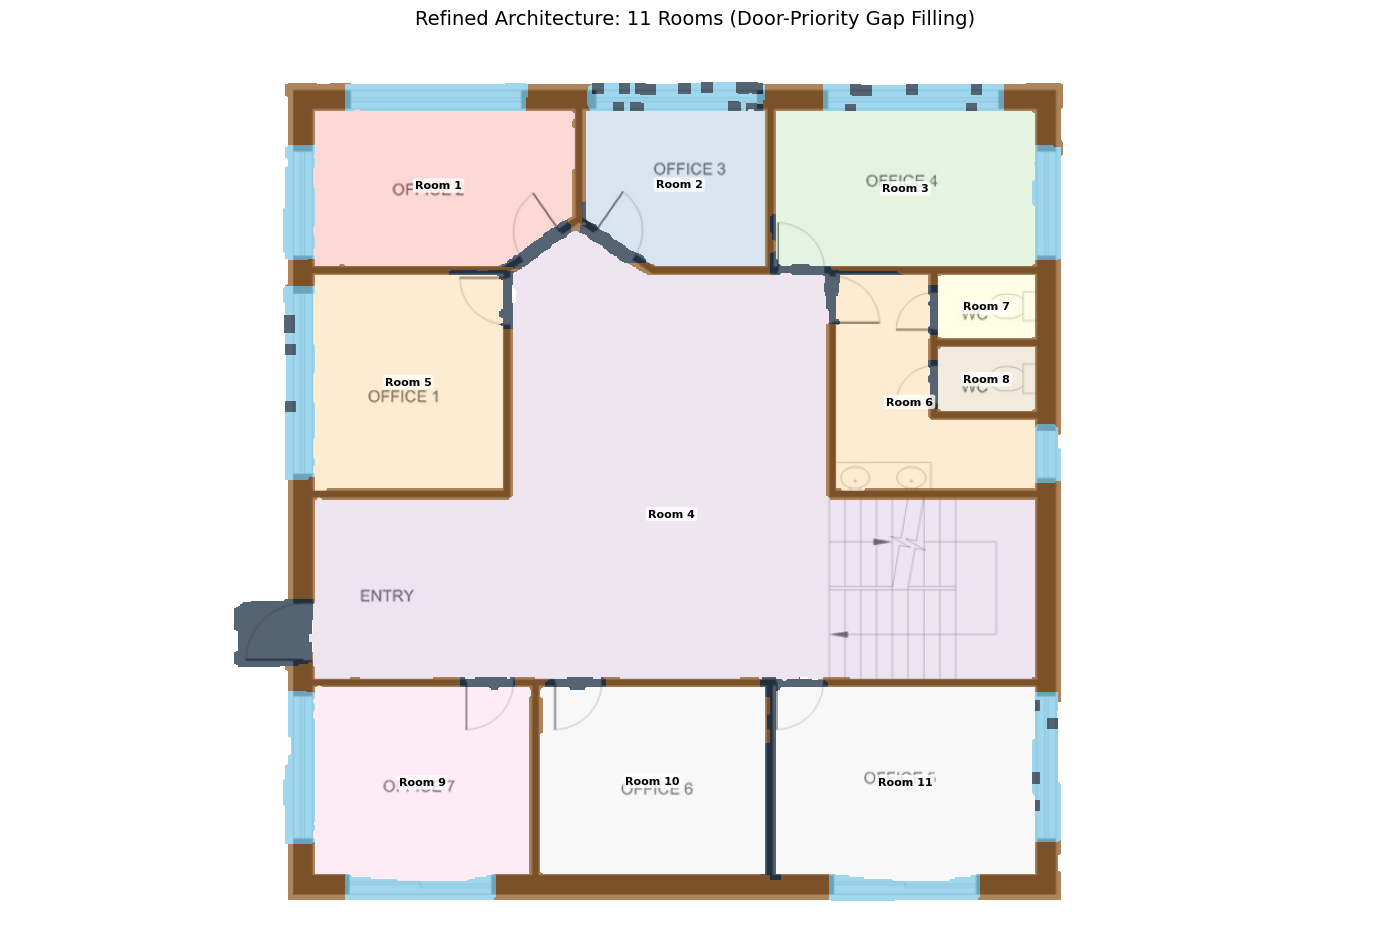

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import label, center_of_mass
from skimage import morphology, transform
from PIL import Image

def generate_pro_floorplan(
    sema_path='sema.csv', 
    split_path='split.csv', 
    underlay_path='input.jpeg',
    smooth=2, 
    square=3, 
    struct_thickness=5,
    alpha_underlay=0.4,
    alpha_struct=0.9,
    alpha_rooms=0.4
):
    """
    Architectural floor plan generator that eliminates gaps between rooms and walls.
    Maintains class labels during expansion and prioritizes doors (class 2) over 
    other structural elements in overlaps.
    """
    # 1. Load Data
    try:
        sema = np.loadtxt(sema_path, delimiter=',')
        split = np.loadtxt(split_path, delimiter=',')
    except Exception as e:
        print(f"Error loading CSV files: {e}")
        return

    # 2. Morphological Straightening Helper
    def refine(mask, sm, sq):
        m = morphology.binary_closing(mask > 0, morphology.disk(sm))
        return morphology.binary_opening(m, morphology.square(sq))

    # Clean the room mask (Class 1 in sema)
    clean_sema = refine(sema == 1, smooth, square)
    
    # 3. Room Segmentation
    rooms, n_rooms = label(clean_sema, structure=np.ones((3, 3)))
    room_mask = (rooms > 0)
    
    # 4. Structure Refinement & Multi-Class Gap Filling
    # Extract unique structural classes (ignoring background)
    unique_classes = np.unique(split)
    unique_classes = unique_classes[unique_classes > 0] 
    
    # PRIORITY LOGIC: We process doors (class 2) LAST so they overwrite 
    # walls (class 1) or windows (class 3) if their dilations overlap.
    # Re-order classes: move 2 to the end of the list if it exists.
    if 1 in unique_classes:
        unique_classes = np.append(unique_classes[unique_classes != 1], 1)
    
    # Prepare a buffer for the final structure
    final_struct = np.zeros_like(split, dtype=int)
    
    for class_id in unique_classes:
        class_mask = (split == class_id)
        # Refine the specific class shape
        refined_class = refine(class_mask, smooth, square)
        
        # Expand the class to fill gaps
        if struct_thickness > 0:
            expanded_class = morphology.dilation(refined_class, morphology.square(struct_thickness))
        else:
            expanded_class = refined_class
            
        # Add to final structure (Overwriting existing pixels because doors are processed last)
        final_struct[expanded_class] = int(class_id)

    # FINAL PRIORITY: Rooms always take precedence over structure
    final_struct = np.where(room_mask, 0, final_struct)

    # --- SAVE OUTPUT FILES ---
    # segmented_rooms.csv: Contains unique room IDs (1, 2, 3...)
    # refined_split.csv: Contains structural classes with door priority
    np.savetxt('segmented_rooms.csv', rooms, delimiter=',', fmt='%d')
    np.savetxt('refined_split.csv', final_struct, delimiter=',', fmt='%d')
    print("Exported: segmented_rooms.csv and refined_split.csv")

    # 5. Visualization
    fig, ax = plt.subplots(figsize=(14, 10))
    
    # --- LAYER 1: Underlay Sketch ---
    try:
        img = Image.open(underlay_path).convert('RGB')
        img_rescaled = transform.resize(np.array(img), split.shape, anti_aliasing=True)
        ax.imshow(img_rescaled, alpha=alpha_underlay)
    except Exception as e:
        ax.imshow(np.ones_like(split), cmap='gray', vmin=0, vmax=1, alpha=0.1)

    # --- LAYER 2: Structure (Preserved Colors: Navy Walls, Brown Doors, Blue Windows) ---
    struct_rgba = np.zeros((*final_struct.shape, 4))
    colors_map = {
        1: [0.17, 0.24, 0.31, alpha_struct], # Walls
        2: [0.60, 0.40, 0.20, alpha_struct], # Doors
        3: [0.53, 0.81, 0.92, alpha_struct], # Windows
    }
    
    for val, color in colors_map.items():
        struct_rgba[final_struct == val] = color
        
    ax.imshow(struct_rgba, interpolation='nearest')

    # --- LAYER 3: Rooms (On Top) ---
    if n_rooms > 0:
        room_rgba = plt.cm.Pastel1(rooms / max(n_rooms, 1))
        room_rgba[..., 3] = room_mask.astype(float) * alpha_rooms
        ax.imshow(room_rgba, interpolation='nearest')

        # --- LAYER 4: Annotations ---
        centers = center_of_mass(room_mask, rooms, range(1, n_rooms + 1))
        for i, (y, x) in enumerate(centers, 1):
            if not np.isnan(y):
                ax.text(x, y, f"Room {i}", color='black', weight='bold', 
                        ha='center', va='center', fontsize=8,
                        bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', boxstyle='round,pad=0.2'))

    ax.set_title(f"Refined Architecture: {n_rooms} Rooms (Door-Priority Gap Filling)", fontsize=14, pad=20)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    generate_pro_floorplan(
        smooth=1, 
        square=1, 
        struct_thickness=10, 
        alpha_underlay=1.0,   
        alpha_struct=0.8,      
        alpha_rooms=0.5        
    )